# Discovering Structure in Unlabeled Data

## Study overview

This notebook investigates a synthetic dataset with three numerical variables and no reference class labels. The objective is to examine its geometric structure and compare two complementary approaches to unsupervised grouping: centroid-based **K-Means** and density-based **DBSCAN**.

The analysis follows a consistent workflow:

1. Inspect the dataset and examine its distributions and projections.
2. Standardize the numerical features to make distance calculations comparable.
3. Apply K-Means with two initialization strategies and examine the resulting centers.
4. Explore candidate cluster counts using parameter search and internal validation metrics.
5. Evaluate DBSCAN under its default and selected neighborhood settings.

**Interpretation note:** Without reference labels, clustering quality must be judged through multiple indicators, not through a conventional classification accuracy score.

## 1. Dataset inspection and exploratory analysis

We begin by reading `data/synthetic_features.csv` into a pandas `DataFrame`. NumPy supports numerical operations, while pandas provides tabular inspection and summary statistics. Imports appear close to the sections where they are needed.

In [1]:
# Suppress non-fatal warnings during the exploratory workflow.
import warnings
warnings.filterwarnings('ignore')

# Load the numerical data-processing libraries.
import numpy as np, pandas as pd
import plotly.io as pio
pio.renderers.default = "png"

# Read the unchanged synthetic observations into a DataFrame.
data = pd.read_csv('data/synthetic_features.csv', sep=',')
data.head()

,att1,att2,att3
0,-3.218423,-0.575000,-3.881158
1,5.801795,-1.340335,-0.201488
2,1.394402,-1.112765,-4.646334
3,4.767334,-2.324507,4.026738
4,4.590624,-1.456617,-1.873809


### 1.1 Dataset structure

`data.info()` reports each feature's data type and non-null count, as well as the dimensions of the table. These checks help establish whether additional cleaning is needed before clustering.

In [2]:
# Inspect feature types, row counts, and missing-value coverage.
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   att1    1500 non-null   float64
 1   att2    1500 non-null   float64
 2   att3    1500 non-null   float64
dtypes: float64(3)
memory usage: 35.3 KB


The provided dataset contains **1,500 observations** and three floating-point features: `att1`, `att2`, and `att3`. All three columns are populated. The names are intentionally generic because the synthetic features have no supplied domain interpretation.

In [3]:
data.describe()

,att1,att2,att3
count,1500.000000,1500.000000,1500.000000
mean,1.590267,-0.031389,-0.420662
std,2.963958,1.750105,3.087797
min,-4.661216,-3.896381,-6.361849
25%,-1.310032,-1.036573,-3.325445
50%,1.726168,-0.360621,-1.101806
75%,4.239675,1.106294,2.619525
max,7.470099,3.763953,6.651459


### 1.2 Descriptive statistics

`data.describe()` summarises the count, mean, sample standard deviation, minimum, quartiles, and maximum for each numerical feature.

- **Mean:** the arithmetic average of the observed values.
- **Standard deviation:** the typical spread of values around their mean.
- **25th, 50th, and 75th percentiles:** reference points dividing the ordered observations into quarters; the 50th percentile is the median.
- **Minimum and maximum:** the endpoints of the observed range.

For values $x_1, \ldots, x_n$ with mean $\bar{x}$, the population standard deviation is

$$\sigma = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})^2}.$$

These summaries reveal scale differences and variation, but they do not by themselves establish how many clusters exist.

### 1.3 Visual exploration

We first inspect the individual feature distributions, followed by pairwise scatter plots and a three-dimensional view. Each visualization provides a different perspective on potential group structure.

array([[<Axes: title={'center': 'att1'}>,
        <Axes: title={'center': 'att2'}>,
        <Axes: title={'center': 'att3'}>]], dtype=object)

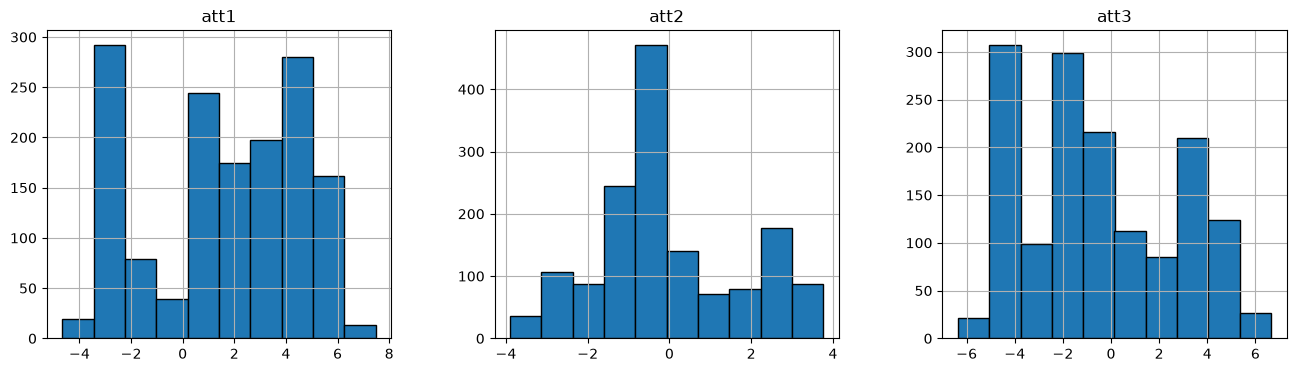

In [4]:
## Compare the distributions of the three numerical features.
data.hist(figsize=(16, 4), layout=(1, len(data.columns)), edgecolor='black')

The histograms highlight the marginal distribution of each attribute. They are useful for assessing spread, skewness, and possible multimodality, but cannot capture the full joint geometry of the three-dimensional observations.

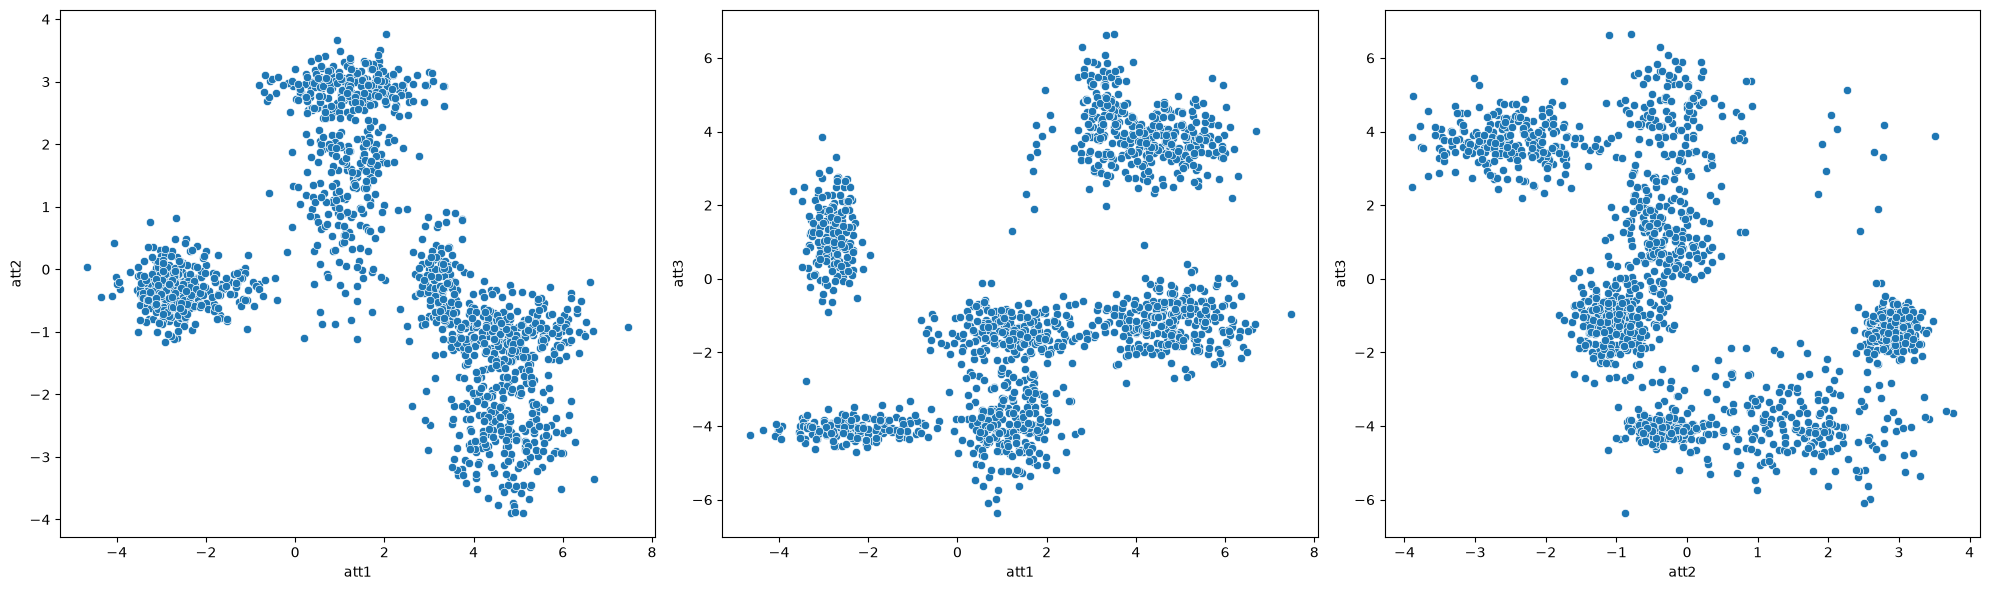

In [5]:
# Import plotting utilities and the pairwise-combination helper.
import matplotlib.pyplot as plt, seaborn as sns
from itertools import combinations

# Build a scatter plot for every distinct pair of attributes.
cols = data.columns
indices_combinations = list(combinations(range(len(cols)), 2))
plt.figure(figsize=(20, 6))
for i, pair in enumerate(indices_combinations):
    plt.subplot(1, len(indices_combinations), i + 1)  # Arrange the plots in a single row.
    sns.scatterplot(data, x=cols[pair[0]], y=cols[pair[1]])
plt.tight_layout()
plt.show()

Pairwise scatter plots make separation and overlap visible in two-feature projections. A group that appears merged in one projection may become distinct in another, so these plots should be interpreted together rather than as definitive evidence of a particular cluster count.

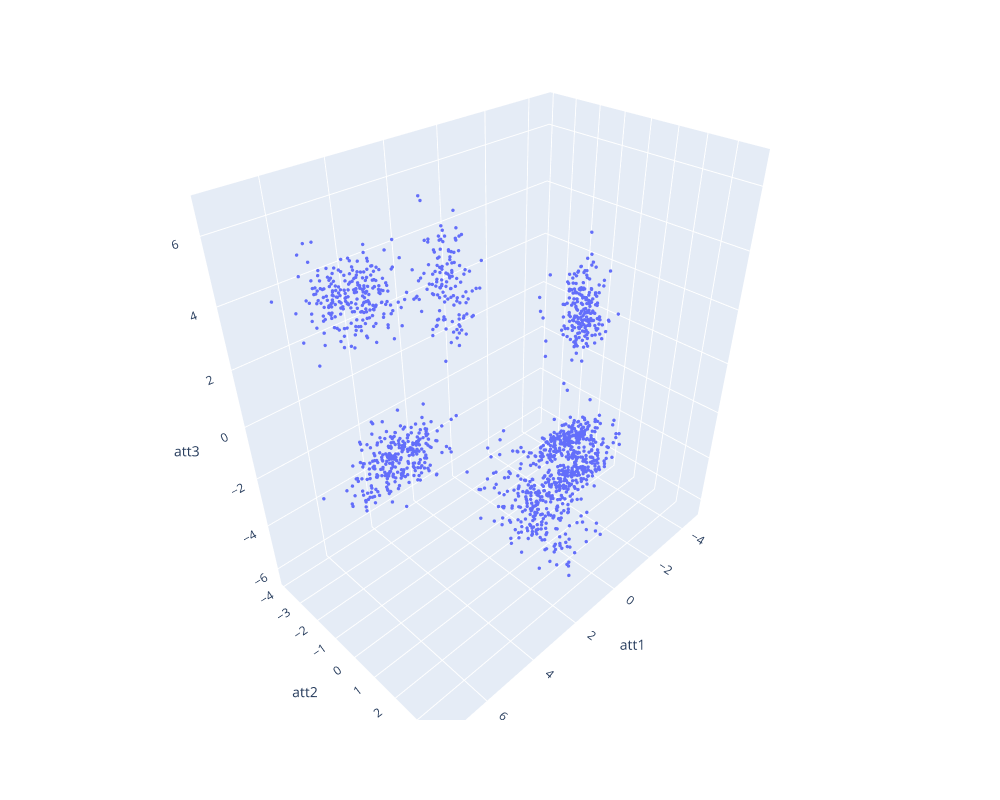

In [6]:
# Use Plotly to examine all three features interactively.
import plotly.express as px

# Create the 3D view with compact point markers.
data_3d = px.scatter_3d(data, x='att1', y='att2', z='att3')
data_3d.update_traces(marker=dict(symbol="circle", size=2)) 

# Set dimensions suitable for exploring the rotated cloud.
data_3d.update_layout(width=1000, height=800)
data_3d.show()

*Visualization: interactive 3D scatter plot of the original numerical features, generated by the preceding code cell.*

### 1.4 Initial geometric observations

In the three-dimensional view, the data appears to contain **approximately seven recognizable groups**. Their centers, extent, and proximity are not uniform: several clouds are compact, while some are elongated or close to neighboring groups. A small number of isolated observations are also visible.

This is a working visual hypothesis, not a known ground truth. Subsequent clustering and validation will test how consistently the structure is recovered.

## 2. Preparing distance-based inputs

Distance-based clustering can be dominated by features with larger numerical scales. We therefore standardize the three attributes using `StandardScaler`, which centers each feature at zero and rescales it to unit variance.

This differs from min–max scaling, which maps the observed feature range to a fixed interval such as [0, 1]. Standardization does not impose fixed bounds; it also does **not** remove the influence of outliers. The same transformed data is used for both clustering methods.

In [7]:
# Import the standardization transform.
from sklearn.preprocessing import StandardScaler
# Instantiate the scaler.
scaler = StandardScaler()
# Estimate feature means and standard deviations.
scaler.fit(data)
# Apply the fitted transformation.
data_transformed = scaler.transform(data)
# Preserve column labels in a new DataFrame.
data_scaled = pd.DataFrame(data_transformed, columns=data.columns)
data_scaled.head()

,att1,att2,att3
0,-1.622929,-0.310720,-1.121074
1,1.421388,-0.748173,0.071004
2,-0.066104,-0.618098,-1.368963
3,1.072258,-1.310712,1.440795
4,1.012618,-0.814639,-0.470767


## 3. K-Means: centroid-based partitioning

K-Means partitions observations into a chosen number of clusters by alternating between nearest-center assignments and center updates. It minimizes within-cluster squared distances and is most natural for groups that are reasonably compact in the standardized feature space.

The initial visualization suggests seven groups, so the first experiments use `n_clusters=7`. This choice remains provisional: K-Means is sensitive to initialization and can split elongated groups or absorb unusual observations into nearby clusters.

### 3.1 Random initialization

We first fit the model with `init='random'`, then inspect assignments, centers, and the geometry of the partition.

In [8]:
# Load the centroid-based clustering estimator.
from sklearn.cluster import KMeans

# Configure the seven-center model with random initialization.
kmeans_random_model = KMeans(n_clusters=7, init='random').set_output(transform='pandas')
# kmeans_random_model = KMeans(n_clusters=7, init='random', random_state=42).set_output(transform='pandas')

# Fit the model and obtain distances to its centers.
results_kmeans_random = kmeans_random_model.fit_transform(data_scaled)
results_kmeans_random.head()

,kmeans0,kmeans1,kmeans2,kmeans3,kmeans4,kmeans5,kmeans6
0,1.843420,3.463915,0.359372,1.645792,2.845981,2.614429,3.802654
1,2.503784,1.869166,3.042012,2.992049,0.506412,2.901512,1.482605
2,1.416908,3.052165,1.316289,2.396330,1.600408,2.515993,3.039862
3,3.545646,1.380103,3.706395,2.944770,1.846213,3.677009,0.149988
4,2.082074,2.226477,2.494036,2.756597,0.342717,2.739123,1.910320


The optional `random_state` parameter controls the pseudo-random initialization. A fixed seed would make repeated runs more reproducible; the active model call below does **not** set one. Consequently, cluster numbering and even some assignments may differ between runs. The commented alternative in the code illustrates a reproducible configuration without changing the current experiment.

In [9]:
kmeans_random_model.labels_

array([2, 4, 2, ..., 4, 0, 2], shape=(1500,), dtype=int32)

In [10]:
kmeans_random_model.cluster_centers_

array([[-0.1376385 ,  0.78061389, -1.15422159],
       [ 0.54829968, -0.03992344,  1.56428278],
       [-1.29303909, -0.18067604, -1.17946316],
       [-1.48204098, -0.17637336,  0.51316294],
       [ 1.07377081, -0.56239522, -0.24696185],
       [-0.11546757,  1.6780571 , -0.34160967],
       [ 1.05463717, -1.42071768,  1.34037269]])

In [11]:
kmeans_random_data = data_scaled.copy()
kmeans_random_data['cluster'] = kmeans_random_model.labels_
kmeans_random_data

,att1,att2,att3,cluster
0,-1.622929,-0.310720,-1.121074,2
1,1.421388,-0.748173,0.071004,4
2,-0.066104,-0.618098,-1.368963,2
3,1.072258,-1.310712,1.440795,6
4,1.012618,-0.814639,-0.470767,4
...,...,...,...,...
1495,-1.403236,-0.291382,0.598679,3
1496,0.779571,-1.754796,1.257213,6
1497,1.167591,-0.642536,-0.400586,4
1498,0.037865,1.006542,-0.703815,0


In [12]:
kmeans_random_centroids = pd.DataFrame(kmeans_random_model.cluster_centers_, columns=data_scaled.columns)
kmeans_random_centroids['cluster'] = ['Centroid 0','Centroid 1','Centroid 2','Centroid 3','Centroid 4','Centroid 5','Centroid 6']
kmeans_random_centroids

,att1,att2,att3,cluster
0,-0.137638,0.780614,-1.154222,Centroid 0
1,0.548300,-0.039923,1.564283,Centroid 1
2,-1.293039,-0.180676,-1.179463,Centroid 2
3,-1.482041,-0.176373,0.513163,Centroid 3
4,1.073771,-0.562395,-0.246962,Centroid 4
5,-0.115468,1.678057,-0.341610,Centroid 5
6,1.054637,-1.420718,1.340373,Centroid 6


<Axes: >

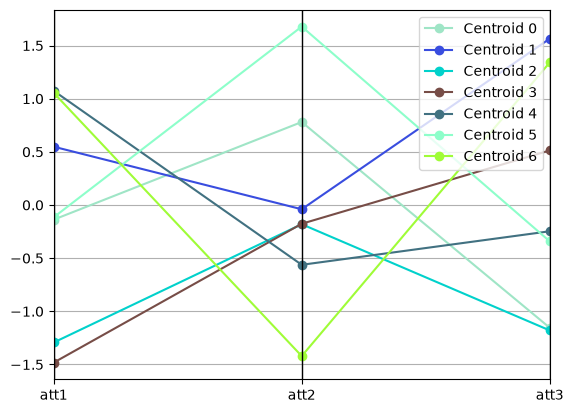

In [13]:
# Load the parallel-coordinate plotting helper.
from pandas.plotting import parallel_coordinates

# Compare the fitted centers across the numerical attributes.
parallel_coordinates(kmeans_random_centroids, 'cluster',  marker='o')

The parallel-coordinate chart compares the fitted centers across all three standardized features. Distinct profiles suggest that the centers represent different parts of feature space, but a single run cannot establish stability across repeated initializations.

In [14]:
kmeans_random_data['cluster'].value_counts()

cluster
4    276
5    244
6    235
2    210
0    201
3    197
1    137
Name: count, dtype: int64

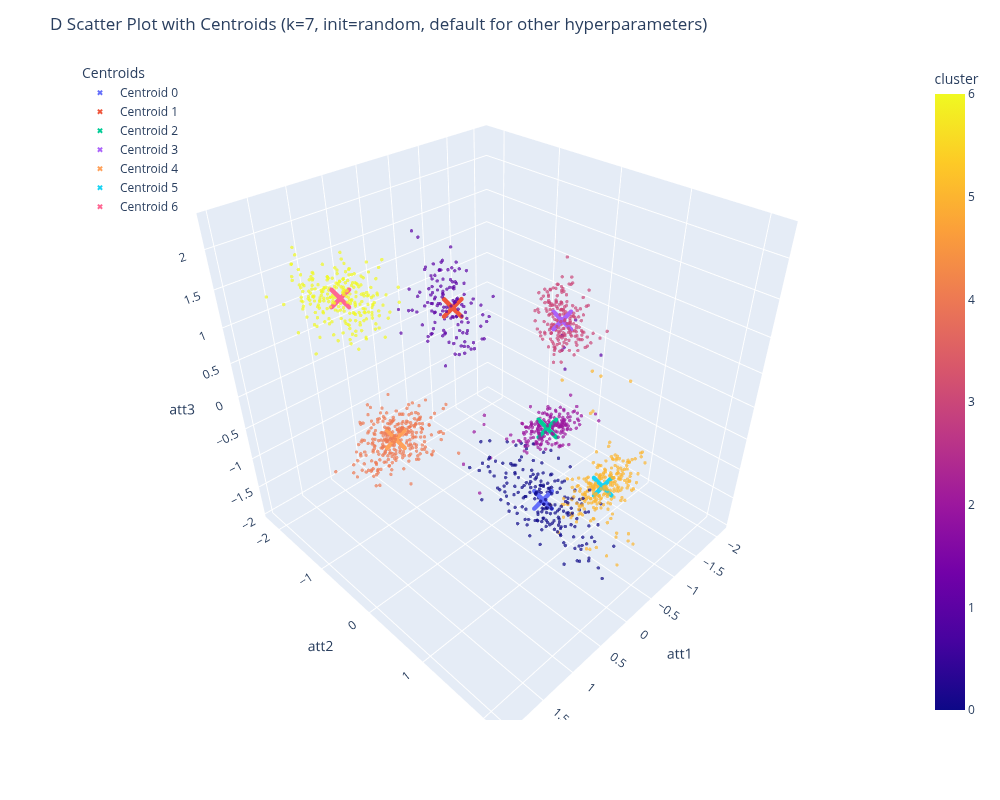

In [15]:
# Show observations colored by their assigned group.
fig_3d_kmeans_random_data = px.scatter_3d(kmeans_random_data, x='att1', y='att2', z='att3', color='cluster')
fig_3d_kmeans_random_data.update_traces(marker=dict(symbol="circle", size=2), opacity=0.7, name="Data")

# Add the fitted cluster centers.
fig_3d_kmeans_random_centroids = px.scatter_3d(kmeans_random_centroids, x='att1', y='att2', z='att3', color='cluster')
fig_3d_kmeans_random_centroids.update_traces(marker=dict(symbol="x", size=5), name="Centroids")

# Overlay center markers and provide a distinct label for each.
for i, trace in enumerate(fig_3d_kmeans_random_centroids.data):
    cluster_value = kmeans_random_centroids['cluster'].iloc[i]
    trace.name = f"{cluster_value}"
    fig_3d_kmeans_random_data.add_trace(trace)

# Position the legend and configure the 3D view.
fig_3d_kmeans_random_data.update_layout(legend=dict(title="Centroids", x=0, xanchor="left",y=1), width=1000, height=800, 
                                        title="D Scatter Plot with Centroids (k=7, init=random, default for other hyperparameters)")

# Reserve space for an additional legend entry.
fig_3d_kmeans_random_data.add_layout_image(dict(source=None,
                                                # Layout placeholder; no image is drawn.
                                                x=1.1, y=1, xanchor="right", yanchor="top", layer="above"))

# Retain the intended centroid legend behavior.
fig_3d_kmeans_random_data.update_traces(selector=dict(name="Centroid"),showlegend=True)
fig_3d_kmeans_random_data.show()

*Visualization: 3D K-Means partition and fitted centroids using random initialization, generated by the preceding code cell.*

The three-dimensional plot allows a visual check of whether centers fall near the main data concentrations and whether the partition follows recognizable groups. This supports a qualitative assessment, not a guarantee that the partition is optimal or stable.

The next code cell assigns two additional standardized feature vectors to their nearest fitted centers. The numeric cluster IDs identify model-specific groups rather than fixed semantic categories.

In [16]:
new_rows = [[0.5, -1.6, -0.2], [-1.5, 1, 0.4]]
kmeans_random_model.predict(new_rows)

array([4, 3], dtype=int32)

### 3.2 K-Means++ initialization

`k-means++` favors more widely separated starting centers: after selecting the first center, later centers are sampled with probabilities linked to squared distances from existing centers. This often reduces sensitivity to poor initial placement.

We repeat the seven-cluster experiment with `init='k-means++'` and compare its fitted centers, group sizes, and predicted cluster assignments with the random-initialization run. Similar-looking outcomes are descriptive rather than proof of equivalent solutions.

In [17]:
kmeans_pp_model = KMeans(n_clusters=7, init='k-means++').set_output(transform='pandas')
results_kmeans_pp = kmeans_pp_model.fit_transform(data_scaled)
results_kmeans_pp.head()

,kmeans0,kmeans1,kmeans2,kmeans3,kmeans4,kmeans5,kmeans6
0,2.608804,3.802654,1.645792,2.845981,0.351263,3.463915,1.831932
1,2.897624,1.482605,2.992049,0.506412,3.052668,1.869166,2.495303
2,2.508943,3.039862,2.396330,1.600408,1.325360,3.052165,1.399504
3,3.674986,0.149988,2.944770,1.846213,3.715773,1.380103,3.537599
4,2.733884,1.910320,2.756597,0.342717,2.504591,2.226477,2.070415


In [18]:
kmeans_pp_model.labels_

array([4, 3, 4, ..., 3, 6, 4], shape=(1500,), dtype=int32)

In [19]:
kmeans_pp_model.cluster_centers_

array([[-0.11540711,  1.67258262, -0.34664101],
       [ 1.05463717, -1.42071768,  1.34037269],
       [-1.48204098, -0.17637336,  0.51316294],
       [ 1.07377081, -0.56239522, -0.24696185],
       [-1.30300836, -0.17971343, -1.18330953],
       [ 0.54829968, -0.03992344,  1.56428278],
       [-0.13924   ,  0.76323971, -1.15643516]])

In [20]:
kmeans_pp_data = data_scaled.copy()
kmeans_pp_data['cluster'] = kmeans_pp_model.labels_
kmeans_pp_data

,att1,att2,att3,cluster
0,-1.622929,-0.310720,-1.121074,4
1,1.421388,-0.748173,0.071004,3
2,-0.066104,-0.618098,-1.368963,4
3,1.072258,-1.310712,1.440795,1
4,1.012618,-0.814639,-0.470767,3
...,...,...,...,...
1495,-1.403236,-0.291382,0.598679,2
1496,0.779571,-1.754796,1.257213,1
1497,1.167591,-0.642536,-0.400586,3
1498,0.037865,1.006542,-0.703815,6


In [21]:
kmeans_pp_centroids = pd.DataFrame(kmeans_pp_model.cluster_centers_, columns=data_scaled.columns)
kmeans_pp_centroids['cluster'] = ['Centroid 0','Centroid 1','Centroid 2','Centroid 3','Centroid 4','Centroid 5','Centroid 6']
kmeans_pp_centroids

,att1,att2,att3,cluster
0,-0.115407,1.672583,-0.346641,Centroid 0
1,1.054637,-1.420718,1.340373,Centroid 1
2,-1.482041,-0.176373,0.513163,Centroid 2
3,1.073771,-0.562395,-0.246962,Centroid 3
4,-1.303008,-0.179713,-1.183310,Centroid 4
5,0.548300,-0.039923,1.564283,Centroid 5
6,-0.139240,0.763240,-1.156435,Centroid 6


<Axes: >

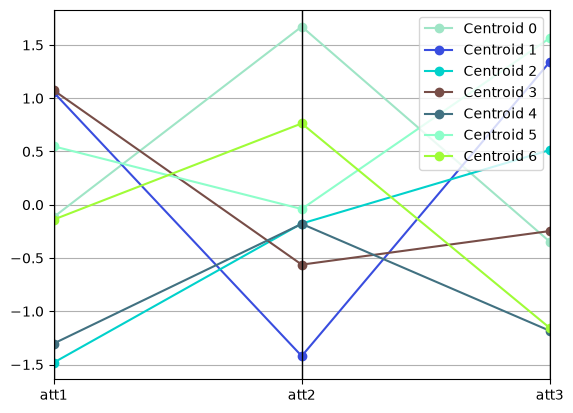

In [22]:
parallel_coordinates(kmeans_pp_centroids, 'cluster',  marker='o')

In [23]:
kmeans_random_data['cluster'].value_counts()

cluster
4    276
5    244
6    235
2    210
0    201
3    197
1    137
Name: count, dtype: int64

In [24]:
kmeans_pp_data['cluster'].value_counts()

cluster
3    276
0    247
1    235
4    208
6    200
2    197
5    137
Name: count, dtype: int64

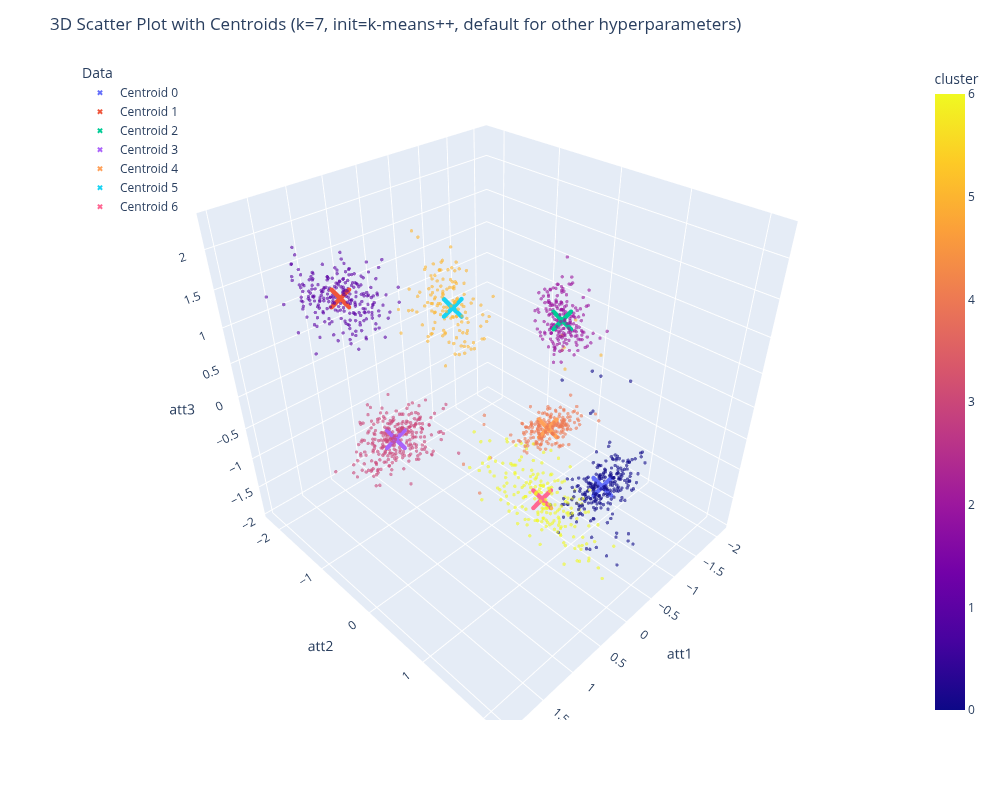

In [25]:
# Plot the observations and their K-Means++ assignments.
fig_3d_kmeans_pp_data = px.scatter_3d(kmeans_pp_data, x='att1', y='att2', z='att3', color='cluster')
fig_3d_kmeans_pp_data.update_traces(marker=dict(symbol="circle", size=2), opacity=0.6, name="Data")

# Visualize the corresponding centers.
fig_3d_kmeans_pp_centroids = px.scatter_3d(kmeans_pp_centroids, x='att1', y='att2', z='att3', color='cluster')
fig_3d_kmeans_pp_centroids.update_traces(marker=dict(symbol="x", size=5), name="Centroids")

# Merge the center traces with the observation figure.
for i, trace in enumerate(fig_3d_kmeans_pp_centroids.data):
    cluster_value = kmeans_pp_centroids['cluster'].iloc[i]
    trace.name = f"{cluster_value}"
    fig_3d_kmeans_pp_data.add_trace(trace)

# Configure the figure title, dimensions, and legend.
fig_3d_kmeans_pp_data.update_layout(legend=dict(title="Data", x=0, xanchor="left", y=1), width=1000, height=800,
                                    title="3D Scatter Plot with Centroids (k=7, init=k-means++, default for other hyperparameters)")

# Keep space for the secondary legend.
fig_3d_kmeans_pp_data.add_layout_image(dict(source=None, x=1.1, y=1, xanchor="right", yanchor="top", layer="above"))

# Apply the final legend selection.
fig_3d_kmeans_pp_data.update_traces(selector=dict(name="Centroid"),showlegend=True)
fig_3d_kmeans_pp_data.show()

*Visualization: 3D K-Means partition and fitted centroids using K-Means++ initialization, generated by the preceding code cell.*

In [26]:
kmeans_pp_model.predict(new_rows)

array([3, 2], dtype=int32)

### 3.3 Exploring K-Means hyperparameters

The grid below compares candidate values for the number of clusters, initialization method, restart count, iteration limit, and random seed. In scikit-learn, the default K-Means score is negative inertia, which rewards smaller within-cluster squared distances.

**Important limitation:** inertia usually decreases as the number of clusters grows. Therefore the grid-search winner should not, by itself, be interpreted as the true number of natural groups; we compare it with the later silhouette and Davies–Bouldin diagnostics.

In [27]:
from sklearn.model_selection import GridSearchCV
# List the K-Means configurations to evaluate.
param_grid = {
    'n_clusters': range(6, 9),
    'init': ['k-means++', 'random'],
    'n_init': [5, 10, 15],
    'max_iter': [100, 200, 300, 400, 500],
    'random_state': [1, 16, 34, 42, 57]
}
# Construct the estimator.
kmeans = KMeans()
# Evaluate the parameter combinations using cross-validation.
grid_search = GridSearchCV(kmeans, param_grid)
grid_search.fit(data_scaled)
# Inspect the parameter set with the highest grid-search score.
grid_search.best_params_

{'init': 'k-means++',
 'max_iter': 100,
 'n_clusters': 8,
 'n_init': 5,
 'random_state': 42}

In [28]:
kmeans_pp_model = KMeans(n_clusters=8, init='k-means++', 
                         n_init=5, max_iter=100, random_state=42).set_output(transform='pandas')
results_kmeans_pp = kmeans_pp_model.fit_transform(data_scaled)
results_kmeans_pp.head()

,kmeans0,kmeans1,kmeans2,kmeans3,kmeans4,kmeans5,kmeans6,kmeans7
0,3.463915,2.626487,1.576359,1.645792,2.849492,2.111302,3.802654,0.328957
1,1.869166,2.892985,2.236389,2.992049,0.502789,2.766163,1.482605,3.078894
2,3.052165,2.531446,0.965681,2.396330,1.603944,1.800002,3.039862,1.354185
3,1.380103,3.654195,3.253315,2.944770,1.843999,3.807676,0.149988,3.735642
4,2.226477,2.738670,1.743436,2.756597,0.344037,2.397203,1.910320,2.532307


In [29]:
kmeans_pp_model.labels_

array([7, 4, 2, ..., 4, 5, 7], shape=(1500,), dtype=int32)

In [30]:
kmeans_pp_model.cluster_centers_

array([[ 0.54829968, -0.03992344,  1.56428278],
       [-0.11393212,  1.67569271, -0.29917103],
       [-0.17087899,  0.30233899, -1.09627725],
       [-1.48204098, -0.17637336,  0.51316294],
       [ 1.076729  , -0.56318516, -0.24488504],
       [-0.1213044 ,  1.17192825, -1.18795106],
       [ 1.05463717, -1.42071768,  1.34037269],
       [-1.33106463, -0.17202671, -1.18264977]])

In [31]:
kmeans_pp_data = data_scaled.copy()
kmeans_pp_data['cluster'] = kmeans_pp_model.labels_
kmeans_pp_data

,att1,att2,att3,cluster
0,-1.622929,-0.310720,-1.121074,7
1,1.421388,-0.748173,0.071004,4
2,-0.066104,-0.618098,-1.368963,2
3,1.072258,-1.310712,1.440795,6
4,1.012618,-0.814639,-0.470767,4
...,...,...,...,...
1495,-1.403236,-0.291382,0.598679,3
1496,0.779571,-1.754796,1.257213,6
1497,1.167591,-0.642536,-0.400586,4
1498,0.037865,1.006542,-0.703815,5


In [32]:
kmeans_pp_centroids = pd.DataFrame(kmeans_pp_model.cluster_centers_, columns=data_scaled.columns)
kmeans_pp_centroids['cluster'] = ['centroid 0','centroid 1','centroid 2','centroid 3','centroid 4','centroid 5','centroid 6','centroid 7']
kmeans_pp_centroids

,att1,att2,att3,cluster
0,0.548300,-0.039923,1.564283,centroid 0
1,-0.113932,1.675693,-0.299171,centroid 1
2,-0.170879,0.302339,-1.096277,centroid 2
3,-1.482041,-0.176373,0.513163,centroid 3
4,1.076729,-0.563185,-0.244885,centroid 4
5,-0.121304,1.171928,-1.187951,centroid 5
6,1.054637,-1.420718,1.340373,centroid 6
7,-1.331065,-0.172027,-1.182650,centroid 7


<Axes: >

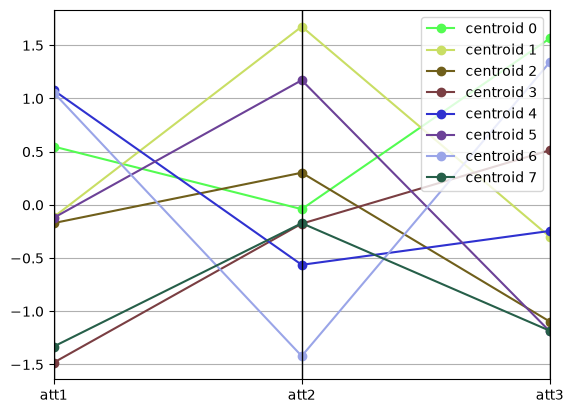

In [33]:
parallel_coordinates(kmeans_pp_centroids, 'cluster',  marker='o')

In [34]:
kmeans_pp_data['cluster'].value_counts()

cluster
4    275
6    235
1    232
7    202
3    197
0    137
5    124
2     98
Name: count, dtype: int64

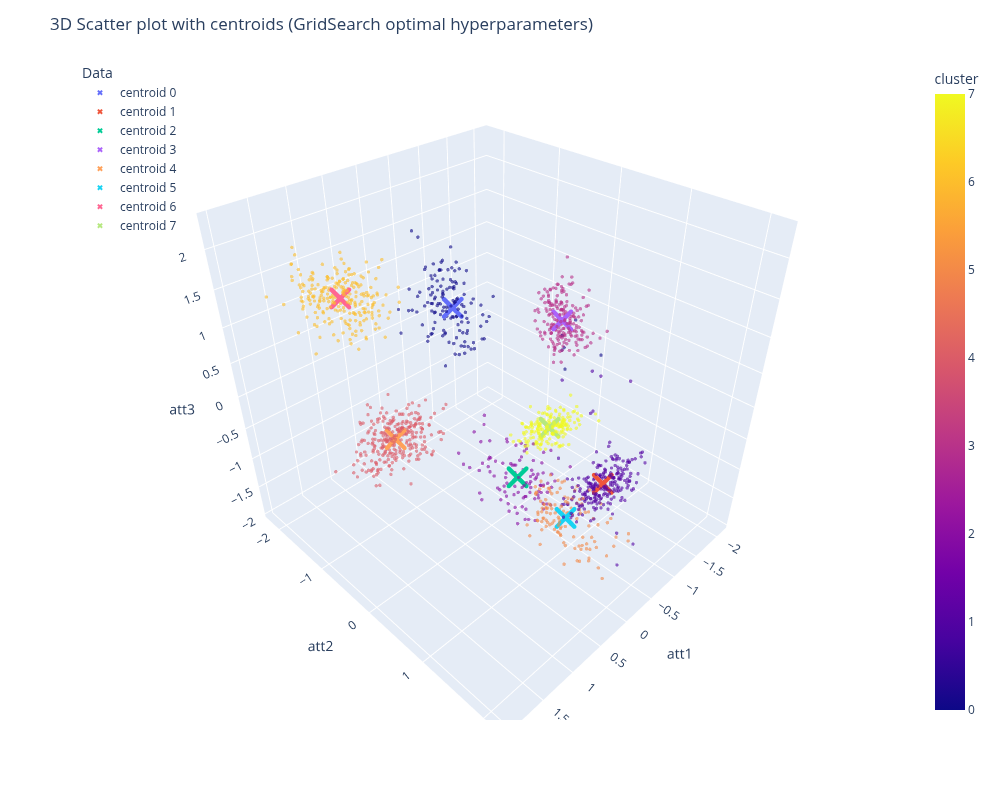

In [35]:
# Draw points grouped by the fitted eight-cluster partition.
fig_3d_kmeans_pp_data = px.scatter_3d(kmeans_pp_data, x='att1', y='att2', z='att3', color='cluster')
fig_3d_kmeans_pp_data.update_traces(marker=dict(symbol="circle", size=2), opacity=0.6, name="Data")

# Plot the eight fitted centroids.
fig_3d_kmeans_pp_centroids = px.scatter_3d(kmeans_pp_centroids, x='att1', y='att2', z='att3', color='cluster')
fig_3d_kmeans_pp_centroids.update_traces(marker=dict(symbol="x", size=5), name="Centroids")

# Overlay the center markers and their labels.
for i, trace in enumerate(fig_3d_kmeans_pp_centroids.data):
    cluster_value = kmeans_pp_centroids['cluster'].iloc[i]
    trace.name = f"{cluster_value}"
    fig_3d_kmeans_pp_data.add_trace(trace)

# Configure the combined three-dimensional figure.
fig_3d_kmeans_pp_data.update_layout(legend=dict(title="Data", x=0, xanchor="left", y=1), width=1000, height=800, 
                                    title="3D Scatter plot with centroids (GridSearch optimal hyperparameters)")  

# Keep a placeholder for an auxiliary legend.
fig_3d_kmeans_pp_data.add_layout_image(dict(source=None,# Layout placeholder; no image is drawn.
                                            x=1.1, y=1, xanchor="right", yanchor="top", layer="above"))

# Retain the selected centroid legend entries.
fig_3d_kmeans_pp_data.update_traces(selector=dict(name="Centroid"),showlegend=True)
fig_3d_kmeans_pp_data.show()

*Visualization: 3D K-Means partition using the manually specified eight-cluster configuration, generated by the preceding code cell.*

### 3.4 Comparing seven and eight clusters

The eight-cluster configuration divides one of the more elongated regions that appears as a single group in the seven-cluster view. This illustrates a familiar tension: an additional centroid can reduce inertia even when it does not correspond to an independently meaningful population.

K-Means also assumes a centroid-based notion of similarity and assigns every observation to a cluster, including points that might otherwise be regarded as noise. To assess whether seven or eight groups provide a better summary, we use supplementary cluster-quality measures.

### 3.5 Internal validation

Since no reference labels are available, the following diagnostics compare within-group compactness and between-group separation. Their results should be interpreted alongside the plots and the assumptions of K-Means.

#### Elbow inspection

We plot the fitted inertia over candidate values of `k`. A pronounced change in slope may indicate a useful compromise between model complexity and residual within-cluster variation, although the elbow is not always sharp.

Text(0, 0.5, 'Inertia')

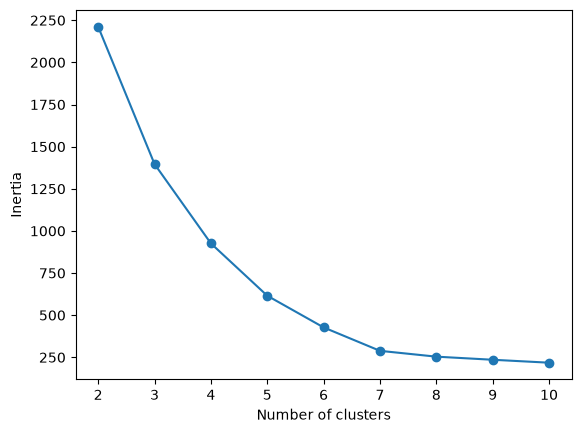

In [36]:
inertias = []
for k in range(2, 11):
    # Hold the remaining configuration values fixed while varying k.
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=5, max_iter=100, random_state=42)
    kmeans.fit(data_scaled)
    inertias.append(kmeans.inertia_)
plt.plot(range(2, 11), inertias, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')

#### Silhouette and Davies–Bouldin indices

The **silhouette score** compares how close observations are to their own cluster versus nearby alternatives; higher values are generally preferable. The **Davies–Bouldin index** compares cluster dispersion with separation; lower values are preferable. Neither score provides a definitive ground truth for group count.

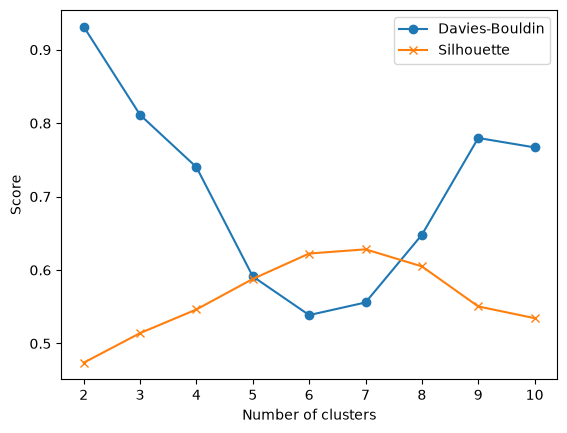

In [37]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
db_scores = []
sil_scores = []
for k in range(2, 11):
  kmeans = KMeans(n_clusters=k, init='k-means++', n_init=5, max_iter=100, random_state=42)
  labels = kmeans.fit_predict(data_scaled)
  db_scores.append(davies_bouldin_score(data_scaled, labels))
  sil_scores.append(silhouette_score(data_scaled, labels))
plt.subplots()
plt.plot(range(2, 11), db_scores, marker='o')
plt.plot(range(2, 11), sil_scores, marker='x')
plt.xlabel('Number of clusters')
plt.ylabel('Score')
plt.legend(['Davies-Bouldin', 'Silhouette'])

### 3.6 Interpreting the K-Means diagnostics

The visual inspection suggests around **seven** coherent regions. The inertia curve may not have a single unambiguous elbow, while the silhouette and Davies–Bouldin curves provide complementary information about the tradeoff between compactness and separation.

A solution with eight centers can improve the K-Means objective by splitting an elongated group, but the additional partition is not necessarily more meaningful. In this notebook, seven clusters remain a plausible interpretation based on the geometry; the model-selection metrics should be read as supporting evidence rather than an absolute verdict.

## 4. DBSCAN: grouping by local density

DBSCAN defines clusters as connected regions of sufficiently dense observations. Its `eps` parameter sets the neighborhood radius, and `min_samples` sets the local support required for a core point. Observations not assigned to a dense region receive the noise label `-1`.

Unlike K-Means, DBSCAN does not require an explicit cluster count and can describe non-spherical structures. Its main limitation is sensitivity to neighborhood parameters, especially when different groups have substantially different densities.

### 4.1 Baseline configuration

We first fit DBSCAN using its default settings, then inspect the assigned groups and noise count.

In [38]:
from sklearn.cluster import DBSCAN
dbscan_model = DBSCAN()
dbscan_labels = dbscan_model.fit_predict(data_scaled)
dbscan_data = data_scaled.copy()
dbscan_data['cluster'] = dbscan_model.labels_
dbscan_data

,att1,att2,att3,cluster
0,-1.622929,-0.310720,-1.121074,0
1,1.421388,-0.748173,0.071004,0
2,-0.066104,-0.618098,-1.368963,0
3,1.072258,-1.310712,1.440795,0
4,1.012618,-0.814639,-0.470767,0
...,...,...,...,...
1495,-1.403236,-0.291382,0.598679,1
1496,0.779571,-1.754796,1.257213,0
1497,1.167591,-0.642536,-0.400586,0
1498,0.037865,1.006542,-0.703815,0


In [39]:
dbscan_data.groupby('cluster')['cluster'].value_counts()

cluster
-1       2
 0    1290
 1     197
 2      11
Name: count, dtype: int64

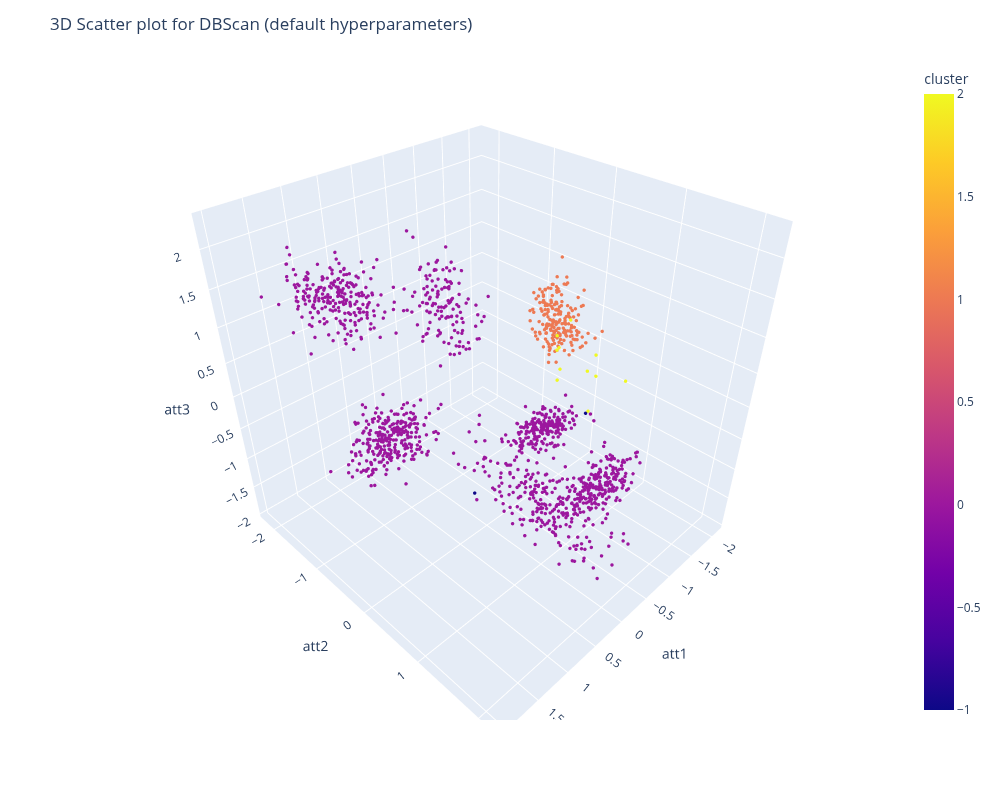

In [40]:
fig_3d_dbscan_data = px.scatter_3d(dbscan_data, x='att1', y='att2', z='att3', color='cluster')
fig_3d_dbscan_data.update_traces(marker=dict(symbol="circle", size=2), name="Data")
fig_3d_dbscan_data.update_layout(width=1000, height=800,
                                 title="3D Scatter plot for DBScan (default hyperparameters)")
fig_3d_dbscan_data.show()

*Visualization: 3D DBSCAN labels under the library's default parameters, generated by the preceding code cell.*

### 4.2 Reading the baseline result

With default settings (`eps=0.5`, `min_samples=5`), the original analysis reports **three clusters and two noise observations**. Compared with the roughly seven visually distinguishable regions, this suggests that the neighborhood radius joins areas that appear separate in the scatter plot.

We therefore examine neighborhood distances and try alternative parameter values. Choosing `min_samples` relative to the number of dimensions is a heuristic, not a hard correctness criterion. Likewise, the number of noise observations is not known in advance and should not be treated as a target to match.

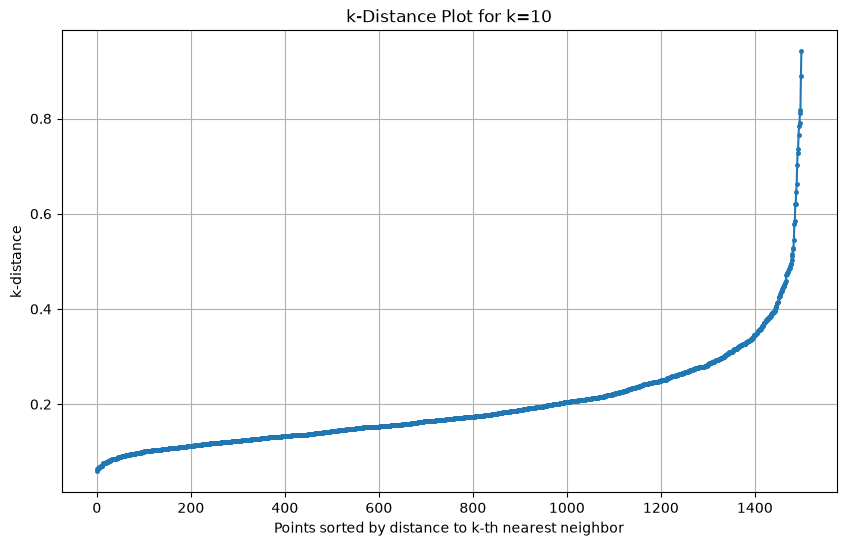

In [41]:
from sklearn.neighbors import NearestNeighbors

def plot_k_distance(k):
    nbrs = NearestNeighbors(n_neighbors=k).fit(data_scaled)
    # Obtain the distances to each point's k nearest neighbors.
    distances, indices = nbrs.kneighbors(data_scaled)
    # Sort distances to the k-th nearest neighbor.
    distances = np.sort(distances[:, k - 1])  # The k-th entry has zero-based index k - 1.
    # Display the ordered neighbor-distance profile.
    plt.figure(figsize=(10, 6))
    plt.plot(distances, marker='o', markersize=2.5)
    plt.ylabel('k-distance')
    plt.xlabel('Points sorted by distance to k-th nearest neighbor')
    plt.title(f'k-Distance Plot for k={k}')
    plt.grid(True)
    plt.show()

k = 10
plot_k_distance(k)

### 4.3 Neighborhood-parameter exploration

The nearest-neighbor distance curve helps identify candidate radii where neighborhoods begin to expand more rapidly. The following search explores `eps` values from `0.20` up to, but not including, `1.00` in increments of `0.01`, and `min_samples` values from 4 through 9.

**Scoring caveat:** `silhouette_score` is passed directly to `GridSearchCV` in the existing code. That metric is not, on its own, a compatible `(estimator, X, y)` grid-search scoring function for DBSCAN. Therefore `best_params_` should not be treated as a validated optimum without a properly defined clustering scorer. The original computation is intentionally left unchanged.

In [42]:
from sklearn.metrics import silhouette_score
param_grid = {
    'eps': np.arange(0.2, 1, 0.01),
    'min_samples': range(4, 10)
}
dbscan = DBSCAN()
grid_search = GridSearchCV(dbscan, param_grid, scoring=silhouette_score)
grid_search.fit(data_scaled)
grid_search.best_params_

{'eps': np.float64(0.2), 'min_samples': 4}

### 4.4 Selected DBSCAN configuration

The notebook next applies `eps=0.23` and `min_samples=4`, rather than relying solely on the grid-search output. These parameters are assessed by inspecting the resulting cluster assignments and their spatial distribution.

The earlier narrative reported **seven clusters and 73 noise observations** for this setting; treat those counts as prior observations to verify when running the notebook, not as values established by the parameter search alone.

In [43]:
dbscan_model = DBSCAN(eps=0.23, min_samples=4)
dbscan_labels = dbscan_model.fit_predict(data_scaled)
dbscan_data = data_scaled.copy()
dbscan_data['cluster'] = dbscan_model.labels_
dbscan_data

,att1,att2,att3,cluster
0,-1.622929,-0.310720,-1.121074,0
1,1.421388,-0.748173,0.071004,1
2,-0.066104,-0.618098,-1.368963,-1
3,1.072258,-1.310712,1.440795,2
4,1.012618,-0.814639,-0.470767,1
...,...,...,...,...
1495,-1.403236,-0.291382,0.598679,3
1496,0.779571,-1.754796,1.257213,2
1497,1.167591,-0.642536,-0.400586,1
1498,0.037865,1.006542,-0.703815,5


In [44]:
dbscan_data.groupby('cluster')['cluster'].value_counts()

cluster
-1     73
 0    200
 1    265
 2    230
 3    194
 4    124
 5    195
 6    219
Name: count, dtype: int64

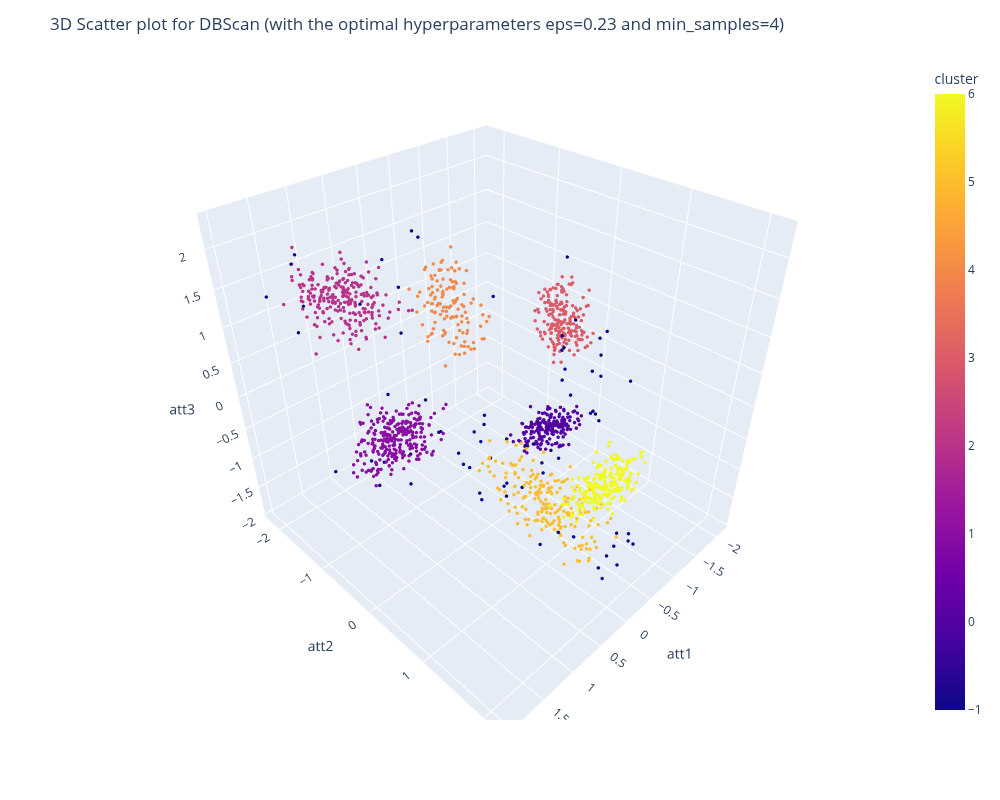

In [45]:
fig_3d_dbscan_data = px.scatter_3d(dbscan_data, x='att1', y='att2', z='att3', color='cluster')
fig_3d_dbscan_data.update_traces(marker=dict(symbol="circle", size=2), name="Data")
fig_3d_dbscan_data.update_layout(width=1000, height=800, title="3D Scatter plot for DBScan (with the optimal hyperparameters eps=0.23 and min_samples=4)")
fig_3d_dbscan_data.show()

*Visualization: 3D DBSCAN labels at `eps=0.23` and `min_samples=4`, generated by the preceding code cell.*

## 5. Summary and limitations

This experiment contrasts two different definitions of a cluster:

- **K-Means** describes observations using a fixed set of centroids and always assigns every sample to one of them.
- **DBSCAN** identifies locally dense connected regions and can leave isolated samples unassigned as noise.

The plots suggest approximately seven natural-looking groups, but this remains an interpretation of synthetic, unlabeled data. The choice between seven and eight K-Means groups depends on the intended level of detail and the validation criteria. DBSCAN's assignments are likewise sensitive to its neighborhood parameters.

**Reproducibility and evaluation:** The active initial K-Means runs do not fix a random seed, and the DBSCAN parameter-search scoring setup warrants review before its output is used to select a model. The code, feature values, and hyperparameters are preserved in this presentation-only revision; rerun the notebook to inspect fresh results.